In [ ]:
import os

# Set working directory"
os.chdir("/home/jmj7858/epifluidlab/sc_nomehic_cellline/gm_sc_new")


In [12]:
import pandas as pd
from collections import defaultdict
from tqdm import tqdm
import gzip

def _open_text(path):
    """Open `path` for text reading, transparently handling .gz."""
    if path.endswith(".gz"):
        return gzip.open(path, "rt")          # "rt" = read text, decodes bytes
    return open(path, "r")

def aggregate_methylation(file_paths):
    meth_counts = defaultdict(float)
    total_counts = defaultdict(int)

    for path in tqdm(file_paths, desc="Aggregating files", unit="file"):
        with _open_text(path) as f:
            for line in f:
                if line.startswith("track") or line.startswith("#"):
                    continue

                cols = line.strip().split('\t')
                if len(cols) < 8:
                    continue

                chr_, start, end = cols[0], int(cols[1]), int(cols[2])
                percent = float(cols[6])
                total = int(cols[7])

                methylated = (percent / 100.0) * total

                key = (chr_, start, end)
                meth_counts[key] += methylated
                total_counts[key] += total

    result = pd.DataFrame(
        [(chr_, start, end,
          meth_counts[(chr_, start, end)],
          total_counts[(chr_, start, end)])
         for (chr_, start, end) in meth_counts.keys()],
        columns=['chr', 'start', 'end',
                 'methylated_reads', 'total_reads']
    )

    return result

In [4]:
prefixes = pd.read_csv('prefixes.txt.gz', header=None)[0].tolist()

In [5]:
prefixes

['scNH_GM_4plex_10_S9.ATCACG',
 'scNH_GM_4plex_10_S9.CGATGT',
 'scNH_GM_4plex_10_S9.GCCAAT',
 'scNH_GM_4plex_10_S9.TGACCA',
 'scNH_GM_4plex_11_S10.ATCACG',
 'scNH_GM_4plex_11_S10.CGATGT',
 'scNH_GM_4plex_11_S10.GCCAAT',
 'scNH_GM_4plex_11_S10.TGACCA',
 'scNH_GM_4plex_12_S11.ATCACG',
 'scNH_GM_4plex_12_S11.CGATGT',
 'scNH_GM_4plex_12_S11.GCCAAT',
 'scNH_GM_4plex_12_S11.TGACCA',
 'scNH_GM_4plex_13_S12.ATCACG',
 'scNH_GM_4plex_13_S12.CGATGT',
 'scNH_GM_4plex_13_S12.GCCAAT',
 'scNH_GM_4plex_13_S12.TGACCA',
 'scNH_GM_4plex_14_S13.ATCACG',
 'scNH_GM_4plex_14_S13.CGATGT',
 'scNH_GM_4plex_14_S13.GCCAAT',
 'scNH_GM_4plex_14_S13.TGACCA',
 'scNH_GM_4plex_15_S14.ATCACG',
 'scNH_GM_4plex_15_S14.CGATGT',
 'scNH_GM_4plex_15_S14.GCCAAT',
 'scNH_GM_4plex_15_S14.TGACCA',
 'scNH_GM_4plex_16_S15.ATCACG',
 'scNH_GM_4plex_16_S15.CGATGT',
 'scNH_GM_4plex_16_S15.GCCAAT',
 'scNH_GM_4plex_16_S15.TGACCA',
 'scNH_GM_4plex_17_S16.ATCACG',
 'scNH_GM_4plex_17_S16.CGATGT',
 'scNH_GM_4plex_17_S16.GCCAAT',
 'scNH_GM_4p

In [13]:
file_paths = [f'07.bistools_snakemake/methylation/{i}/{i}.calmd.cytosine.filtered.sort.HCG.6plus2.bed.gz' for i in prefixes]
result = aggregate_methylation(file_paths)
result[['chr','start','end','methylated_reads','total_reads']][result['chr'].isin('chr'+str(i) for i in range(1,23))].to_csv('HCG_merged.bed', sep='\t', index=False)

Aggregating files: 100%|██████████| 188/188 [03:31<00:00,  1.13s/file]


In [15]:
file_paths = [f'07.bistools_snakemake/methylation/{i}/{i}.calmd.cytosine.filtered.sort.GCH.6plus2.bed.gz' for i in prefixes]
result = aggregate_methylation(file_paths)
result[['chr','start','end','methylated_reads','total_reads']][result['chr'].isin('chr'+str(i) for i in range(1,23))].to_csv('GCH_merged.bed', sep='\t', index=False)

Aggregating files: 100%|██████████| 188/188 [24:19<00:00,  7.76s/file]


In [17]:
GCH = pd.read_csv('GCH_merged.bed', header=None, sep='\t', names=['chr','start','end','methy_count','cov'], skiprows=1)
GCH['bin_id'] = GCH['chr'].astype(str) + '_' + GCH['start'].astype(str) + '_' + GCH['end'].astype(str)
GCH['methylation_level'] = GCH['methy_count'] / GCH['cov']
GCH = GCH[['bin_id','methylation_level','cov']]
GCH.to_csv('GCH_merged_methylation_level_cov.bed', sep='\t', index=False, na_rep='NA')

In [18]:
HCG = pd.read_csv('HCG_merged.bed', header=None, sep='\t', names=['chr','start','end','methy_count','cov'], skiprows=1)
HCG['bin_id'] = HCG['chr'].astype(str) + '_' + HCG['start'].astype(str) + '_' + HCG['end'].astype(str)
HCG['methylation_level'] = HCG['methy_count'] / HCG['cov']
HCG = HCG[['bin_id','methylation_level','cov']]
HCG.to_csv('HCG_merged_methylation_level_cov.bed', sep='\t', index=False, na_rep='NA')

In [19]:
import pandas as pd
import numpy as np

methy = pd.read_csv(
    '../methy/gm12878_methy_count.bed',
    sep='\t',
    names=['chr', 'start', 'end', 'methy_count'],
    header=None
)

cov = pd.read_csv(
    '../methy/gm12878_cov.bed',
    sep='\t',
    names=['chr', 'start', 'end', 'cov'],
    header=None
)

merged = pd.merge(methy, cov, on=['chr', 'start', 'end'], how='inner')

# --- numeric safety ---
merged['start'] = pd.to_numeric(merged['start'], errors='coerce')
merged['end']   = pd.to_numeric(merged['end'], errors='coerce')
merged['methy_count'] = pd.to_numeric(merged['methy_count'], errors='coerce')
merged['cov']         = pd.to_numeric(merged['cov'], errors='coerce')

merged = merged.dropna(subset=['chr','start','end','methy_count','cov'])
merged = merged[merged['cov'] > 0]

# --- keep ONLY 1-bp bins ---
is_1bp = (merged['end'] == merged['start'] + 1)
bad_len = merged[~is_1bp]
print(f"Total rows: {len(merged):,}")
print(f"Non-1bp rows removed: {len(bad_len):,}")

merged = merged[is_1bp].copy()

# --- compute methylation fraction ---
merged['methylation_level'] = merged['methy_count'] / merged['cov']

# --- remove duplicates (same chr/start/end) ---
dup_n = merged.duplicated(subset=['chr','start','end']).sum()
print(f"Duplicate 1-bp coords removed: {dup_n:,}")
merged = merged.drop_duplicates(subset=['chr','start','end'], keep='first')

# --- sort for bedGraphToBigWig ---
merged = merged.sort_values(['chr','start','end'], kind='mergesort')

merged['bin_id'] = merged['chr'].astype(str) + '_' + merged['start'].astype(str) + '_' + merged['end'].astype(str)
merged['methylation_level'] = merged['methy_count'] / merged['cov']
merged = merged[['bin_id','methylation_level','cov']]
merged.to_csv('HCG_mixed_merged_methylation_level_cov.bed', sep='\t', index=False, na_rep='NA')

FileNotFoundError: [Errno 2] No such file or directory: '../methy/gm12878_methy_count.bed'

In [22]:
import pandas as pd
import numpy as np

methy = pd.read_csv(
    '../acc/gm12878_methy_count.bed',
    sep='\t',
    names=['chr', 'start', 'end', 'methy_count'],
    header=None
)

cov = pd.read_csv(
    '../acc/gm12878_cov.bed',
    sep='\t',
    names=['chr', 'start', 'end', 'cov'],
    header=None
)

merged = pd.merge(methy, cov, on=['chr', 'start', 'end'], how='inner')

# --- numeric safety ---
merged['start'] = pd.to_numeric(merged['start'], errors='coerce')
merged['end']   = pd.to_numeric(merged['end'], errors='coerce')
merged['methy_count'] = pd.to_numeric(merged['methy_count'], errors='coerce')
merged['cov']         = pd.to_numeric(merged['cov'], errors='coerce')

merged = merged.dropna(subset=['chr','start','end','methy_count','cov'-])
merged = merged[merged['cov'] > 0]

# --- keep ONLY 1-bp bins ---
is_1bp = (merged['end'] == merged['start'] + 1)
bad_len = merged[~is_1bp]
print(f"Total rows: {len(merged):,}")
print(f"Non-1bp rows removed: {len(bad_len):,}")

merged = merged[is_1bp].copy()

# --- compute methylation fraction ---
merged['methylation_level'] = merged['methy_count'] / merged['cov']

# --- remove duplicates (same chr/start/end) ---
dup_n = merged.duplicated(subset=['chr','start','end']).sum()
print(f"Duplicate 1-bp coords removed: {dup_n:,}")
merged = merged.drop_duplicates(subset=['chr','start','end'], keep='first')

# --- sort for bedGraphToBigWig ---
merged = merged.sort_values(['chr','start','end'], kind='mergesort')

merged['bin_id'] = merged['chr'].astype(str) + '_' + merged['start'].astype(str) + '_' + merged['end'].astype(str)
merged['methylation_level'] = merged['methy_count'] / merged['cov']
merged = merged[['bin_id','methylation_level','cov']]
merged.to_csv('GCH_mixed_merged_methylation_level_cov.bed', sep='\t', index=False, na_rep='NA')

Total rows: 126,620,257
Non-1bp rows removed: 1,501,821
Duplicate 1-bp coords removed: 0


In [20]:
import pandas as pd

def bin_methylation(file_path, size=250_000, has_header=True):
    columns = ['chr', 'start', 'end', 'methylated_reads', 'total_reads']

    # Load data
    if has_header:
        df = pd.read_csv(file_path, sep='\t')
    else:
        df = pd.read_csv(file_path, sep='\t', header=None)
        df.columns = columns

    # Re-bin using start
    df['start'] = (df['start'] // size) * size
    df['end'] = df['start'] + size

    # Group by new bins
    grouped = df.groupby(['chr', 'start', 'end'], as_index=False).agg({
        'methylated_reads': 'sum',
        'total_reads': 'sum'
    })

    # Recalculate methylation level
    grouped['methylation_level'] = grouped['methylated_reads'] / grouped['total_reads']

    return grouped[['chr', 'start', 'end', 'methylation_level', 'methylated_reads', 'total_reads']]


In [22]:
binned = bin_methylation("GCH_merged.bed")
binned.to_csv("gch_pseudobulk_250kb.bed", sep='\t', index=False)


In [23]:
binned = bin_methylation("HCG_merged.bed")
binned.to_csv("hcg_pseudobulk_250kb.bed", sep='\t', index=False)


In [ ]:
binned = bin_methylation("GCH_merged.bed",size=1000)
binned.to_csv("gch_pseudobulk_1kb.bed", sep='\t', index=False)


In [ ]:
binned = bin_methylation("GCH_merged.bed",size=10000)
binned.to_csv("gch_pseudobulk_10kb.bed", sep='\t', index=False)


In [25]:
gm12878_methy_bulk = pd.read_csv('../pseudobulk_vs_bulk/gm12878_bulk_methy_250kb.bed.gz', sep='\t')
gm12878_methy_bulk['gm12878_methy_bulk'] = gm12878_methy_bulk['total_accessible']/gm12878_methy_bulk['total_reads']
gm12878_methy_pseudobulk = pd.read_csv('hcg_pseudobulk_250kb.bed', sep='\t')
gm12878_methy_pseudobulk.columns = ['chr','start','end','gm12878_methy_pseudobulk', 'methylated_reads','total_reads']
gm12878_methy = pd.merge(gm12878_methy_bulk[['chr', 'start', 'end', 'gm12878_methy_bulk']],gm12878_methy_pseudobulk[['chr', 'start', 'end', 'gm12878_methy_pseudobulk']], on=['chr', 'start', 'end'])

GM12878 accessibility Correlation: 0.9817602689798418


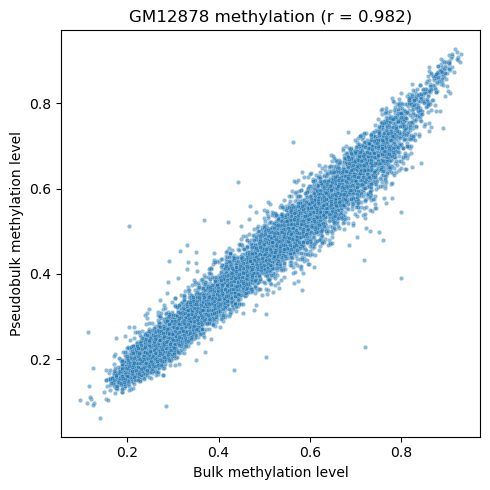

In [27]:
gm12878_methy_corr = gm12878_methy['gm12878_methy_bulk'].corr(gm12878_methy['gm12878_methy_pseudobulk'])
print(f'GM12878 accessibility Correlation: {gm12878_methy_corr}')

import matplotlib.pyplot as plt
import seaborn as sns

# --- Plot ---
plt.figure(figsize=(5, 5))
sns.scatterplot(
    data=gm12878_methy,
    x='gm12878_methy_bulk',
    y='gm12878_methy_pseudobulk',
    s=10,
    alpha=0.5
)

plt.xlabel("Bulk methylation level")
plt.ylabel("Pseudobulk methylation level")
plt.title(f"GM12878 methylation (r = {gm12878_methy_corr:.3f})")

plt.tight_layout()
plt.show()


In [29]:
gm12878_acc_bulk = pd.read_csv('../pseudobulk_vs_bulk/gm12878_bulk_acc_250kb.bed.gz', sep='\t')
gm12878_acc_bulk['gm12878_acc_bulk'] = gm12878_acc_bulk['total_accessible']/gm12878_acc_bulk['total_reads']
gm12878_acc_pseudobulk = pd.read_csv('gch_pseudobulk_250kb.bed', sep='\t')
gm12878_acc_pseudobulk.columns = ['chr','start','end','gm12878_acc_pseudobulk', 'acclated_reads','total_reads']
gm12878_acc_pseudobulk = gm12878_acc_pseudobulk[gm12878_acc_pseudobulk['total_reads'] > 31000]
gm12878_acc = pd.merge(gm12878_acc_bulk[['chr', 'start', 'end', 'gm12878_acc_bulk']],gm12878_acc_pseudobulk[['chr', 'start', 'end', 'gm12878_acc_pseudobulk']], on=['chr', 'start', 'end'])
gm12878_acc = gm12878_acc[(gm12878_acc['gm12878_acc_bulk'] < 0.67) & (gm12878_acc['gm12878_acc_bulk'] > 0.55)]

In [30]:
import numpy as np

def quantile_normalize(target, reference):
    """
    Quantile normalize 'target' distribution to match 'reference'.
    
    target: array-like (e.g., pseudobulk)
    reference: array-like (e.g., bulk)
    """
    target = np.asarray(target, dtype=float)
    reference = np.asarray(reference, dtype=float)

    # sort both
    target_order = np.argsort(target)
    ref_sorted = np.sort(reference)

    # create output
    normalized = np.empty_like(target)

    # assign reference quantiles to target ranks
    normalized[target_order] = ref_sorted

    return normalized

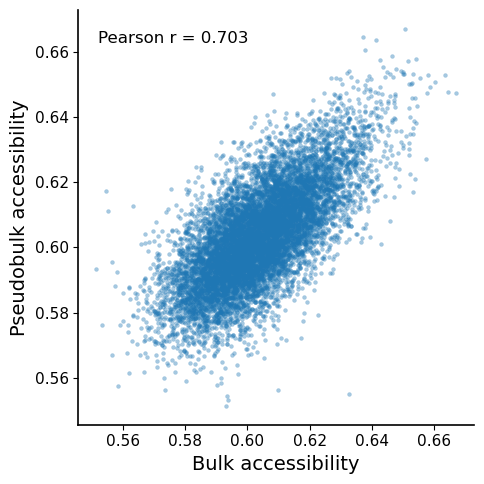

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# ---------------------------
# Compute correlations safely
# ---------------------------
x = gm12878_acc['gm12878_acc_bulk'].to_numpy(dtype=float)
y = gm12878_acc['gm12878_acc_pseudobulk'].to_numpy(dtype=float)


mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

# ---------------------------
# Quantile normalization
# ---------------------------
y_qn = quantile_normalize(y, x)

pear_r, pear_p = pearsonr(x, y)
spear_r, spear_p = spearmanr(x, y)

pear_r_qn, pear_p_qn = pearsonr(x, y_qn)
spear_r_qn, spear_p_qn = spearmanr(x, y_qn)

# ---------------------------
# Styling
# ---------------------------
plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "axes.linewidth": 1.2,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

fig, ax = plt.subplots(figsize=(5, 5))

# Scatter
sns.scatterplot(
    x=x,
    y=y_qn,
    s=8,
    alpha=0.4,
    edgecolor=None,
    ax=ax
)

# Regression line
# sns.regplot(
#     x=x,
#     y=y,
#     scatter=False,
#     ax=ax,
#     line_kws={"color": "black", "linewidth": 1.5}
# )

# Make axes equal
# lim_min = min(x.min(), y.min())
# lim_max = max(x.max(), y.max())
# ax.set_xlim(lim_min, lim_max)
# ax.set_ylim(lim_min, lim_max)
# ax.set_aspect('equal', adjustable='box')

# Labels
ax.set_xlabel("Bulk accessibility")
ax.set_ylabel("Pseudobulk accessibility")

# Correlation annotation inside panel
ax.text(
    0.05, 0.95,
    f"Pearson r = {pear_r_qn:.3f}",
    transform=ax.transAxes,
    verticalalignment="top"
)

sns.despine()
plt.tight_layout()

# Save as vector (important for publication)
plt.savefig("../figures/GM12878_accessibility_correlation_qn.pdf")
plt.show()

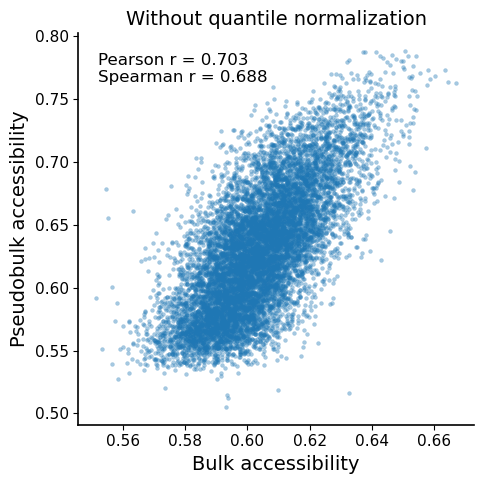

In [32]:
# Plot comparison without quantile normalization
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# ---------------------------
# Compute correlations safely
# ---------------------------
x = gm12878_acc['gm12878_acc_bulk'].to_numpy(dtype=float)
y = gm12878_acc['gm12878_acc_pseudobulk'].to_numpy(dtype=float)

mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

pear_r, pear_p = pearsonr(x, y)
spear_r, spear_p = spearmanr(x, y)

# ---------------------------
# Styling
# ---------------------------
plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "axes.linewidth": 1.2,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

fig, ax = plt.subplots(figsize=(5, 5))

sns.scatterplot(
    x=x,
    y=y,
    s=8,
    alpha=0.4,
    edgecolor=None,
    ax=ax
)

ax.set_xlabel("Bulk accessibility")
ax.set_ylabel("Pseudobulk accessibility")
ax.set_title("Without quantile normalization")

ax.text(
    0.05, 0.95,
    f"Pearson r = {pear_r:.3f}\nSpearman r = {spear_r:.3f}",
    transform=ax.transAxes,
    verticalalignment="top"
)

sns.despine()
plt.tight_layout()
plt.savefig("../figures/GM12878_accessibility_correlation_no_qn.pdf")
plt.show()


In [12]:
gm12878_acc_bulk = pd.read_csv('../pseudobulk_vs_bulk/gm12878_bulk_acc_1kb.bed', sep='\t')
gm12878_acc_bulk['gm12878_acc_bulk'] = gm12878_acc_bulk['total_accessible']/gm12878_acc_bulk['total_reads']
# gm12878_acc_bulk = gm12878_acc_bulk[gm12878_acc_bulk['total_reads'] > 100]
gm12878_acc_pseudobulk = pd.read_csv('gch_pseudobulk_1kb.bed', sep='\t')
gm12878_acc_pseudobulk.columns = ['chr','start','end','gm12878_acc_pseudobulk', 'acclated_reads','total_reads']
# gm12878_acc_pseudobulk = gm12878_acc_pseudobulk[gm12878_acc_pseudobulk['total_reads'] > 200]
gm12878_acc = pd.merge(gm12878_acc_bulk[['chr', 'start', 'end', 'gm12878_acc_bulk']],gm12878_acc_pseudobulk[['chr', 'start', 'end', 'gm12878_acc_pseudobulk']], on=['chr', 'start', 'end'])

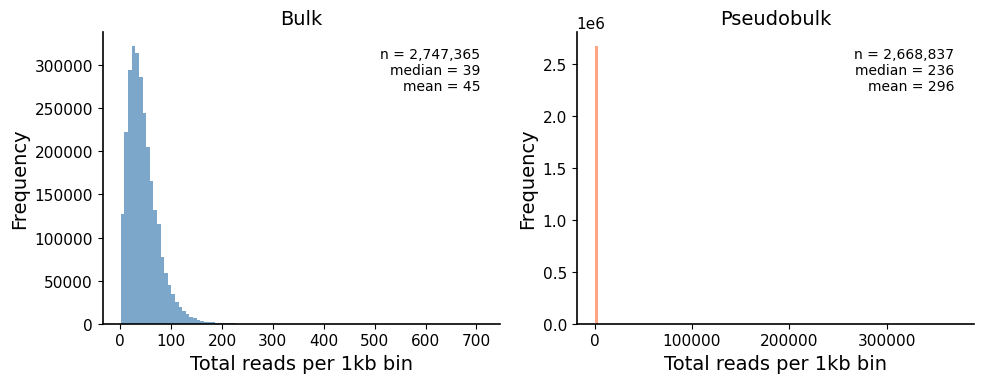

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bulk coverage distribution
axes[0].hist(gm12878_acc_bulk['total_reads'], bins=100, color='steelblue', edgecolor='none', alpha=0.7)
axes[0].set_xlabel('Total reads per 1kb bin')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Bulk')
axes[0].text(0.95, 0.95, f"n = {len(gm12878_acc_bulk):,}\nmedian = {gm12878_acc_bulk['total_reads'].median():.0f}\nmean = {gm12878_acc_bulk['total_reads'].mean():.0f}",
             transform=axes[0].transAxes, va='top', ha='right', fontsize=10)

# Pseudobulk coverage distribution
axes[1].hist(gm12878_acc_pseudobulk['total_reads'], bins=100, color='coral', edgecolor='none', alpha=0.7)
axes[1].set_xlabel('Total reads per 1kb bin')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Pseudobulk')
axes[1].text(0.95, 0.95, f"n = {len(gm12878_acc_pseudobulk):,}\nmedian = {gm12878_acc_pseudobulk['total_reads'].median():.0f}\nmean = {gm12878_acc_pseudobulk['total_reads'].mean():.0f}",
             transform=axes[1].transAxes, va='top', ha='right', fontsize=10)

sns.despine()
plt.tight_layout()
plt.savefig("../figures/GM12878_coverage_distribution.pdf")
plt.show()

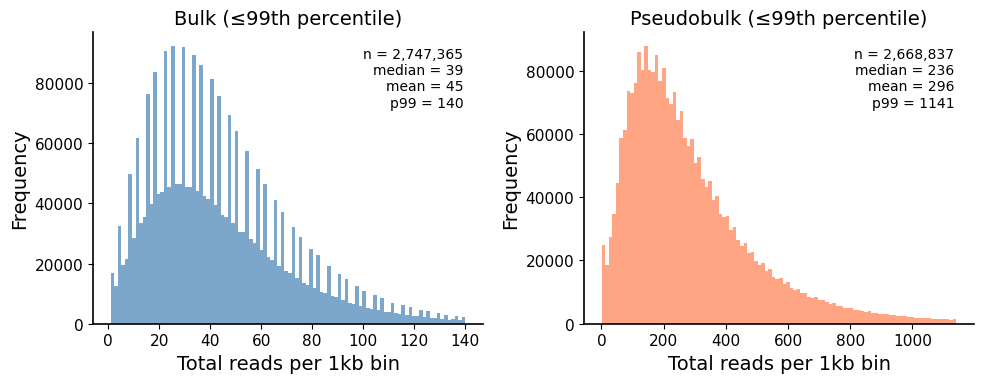

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Compute 99th percentile cutoffs
bulk_99 = gm12878_acc_bulk['total_reads'].quantile(0.99)
pseudo_99 = gm12878_acc_pseudobulk['total_reads'].quantile(0.99)

# Bulk
bulk_data = gm12878_acc_bulk['total_reads'][gm12878_acc_bulk['total_reads'] <= bulk_99]
axes[0].hist(bulk_data, bins=100, color='steelblue', edgecolor='none', alpha=0.7)
axes[0].set_xlabel('Total reads per 1kb bin')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Bulk (≤99th percentile)')
axes[0].text(0.95, 0.95, f"n = {len(gm12878_acc_bulk):,}\nmedian = {gm12878_acc_bulk['total_reads'].median():.0f}\nmean = {gm12878_acc_bulk['total_reads'].mean():.0f}\np99 = {bulk_99:.0f}",
             transform=axes[0].transAxes, va='top', ha='right', fontsize=10)

# Pseudobulk
pseudo_data = gm12878_acc_pseudobulk['total_reads'][gm12878_acc_pseudobulk['total_reads'] <= pseudo_99]
axes[1].hist(pseudo_data, bins=100, color='coral', edgecolor='none', alpha=0.7)
axes[1].set_xlabel('Total reads per 1kb bin')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Pseudobulk (≤99th percentile)')
axes[1].text(0.95, 0.95, f"n = {len(gm12878_acc_pseudobulk):,}\nmedian = {gm12878_acc_pseudobulk['total_reads'].median():.0f}\nmean = {gm12878_acc_pseudobulk['total_reads'].mean():.0f}\np99 = {pseudo_99:.0f}",
             transform=axes[1].transAxes, va='top', ha='right', fontsize=10)

sns.despine()
plt.tight_layout()
plt.savefig("../figures/GM12878_coverage_distribution_99pct.pdf")
plt.show()

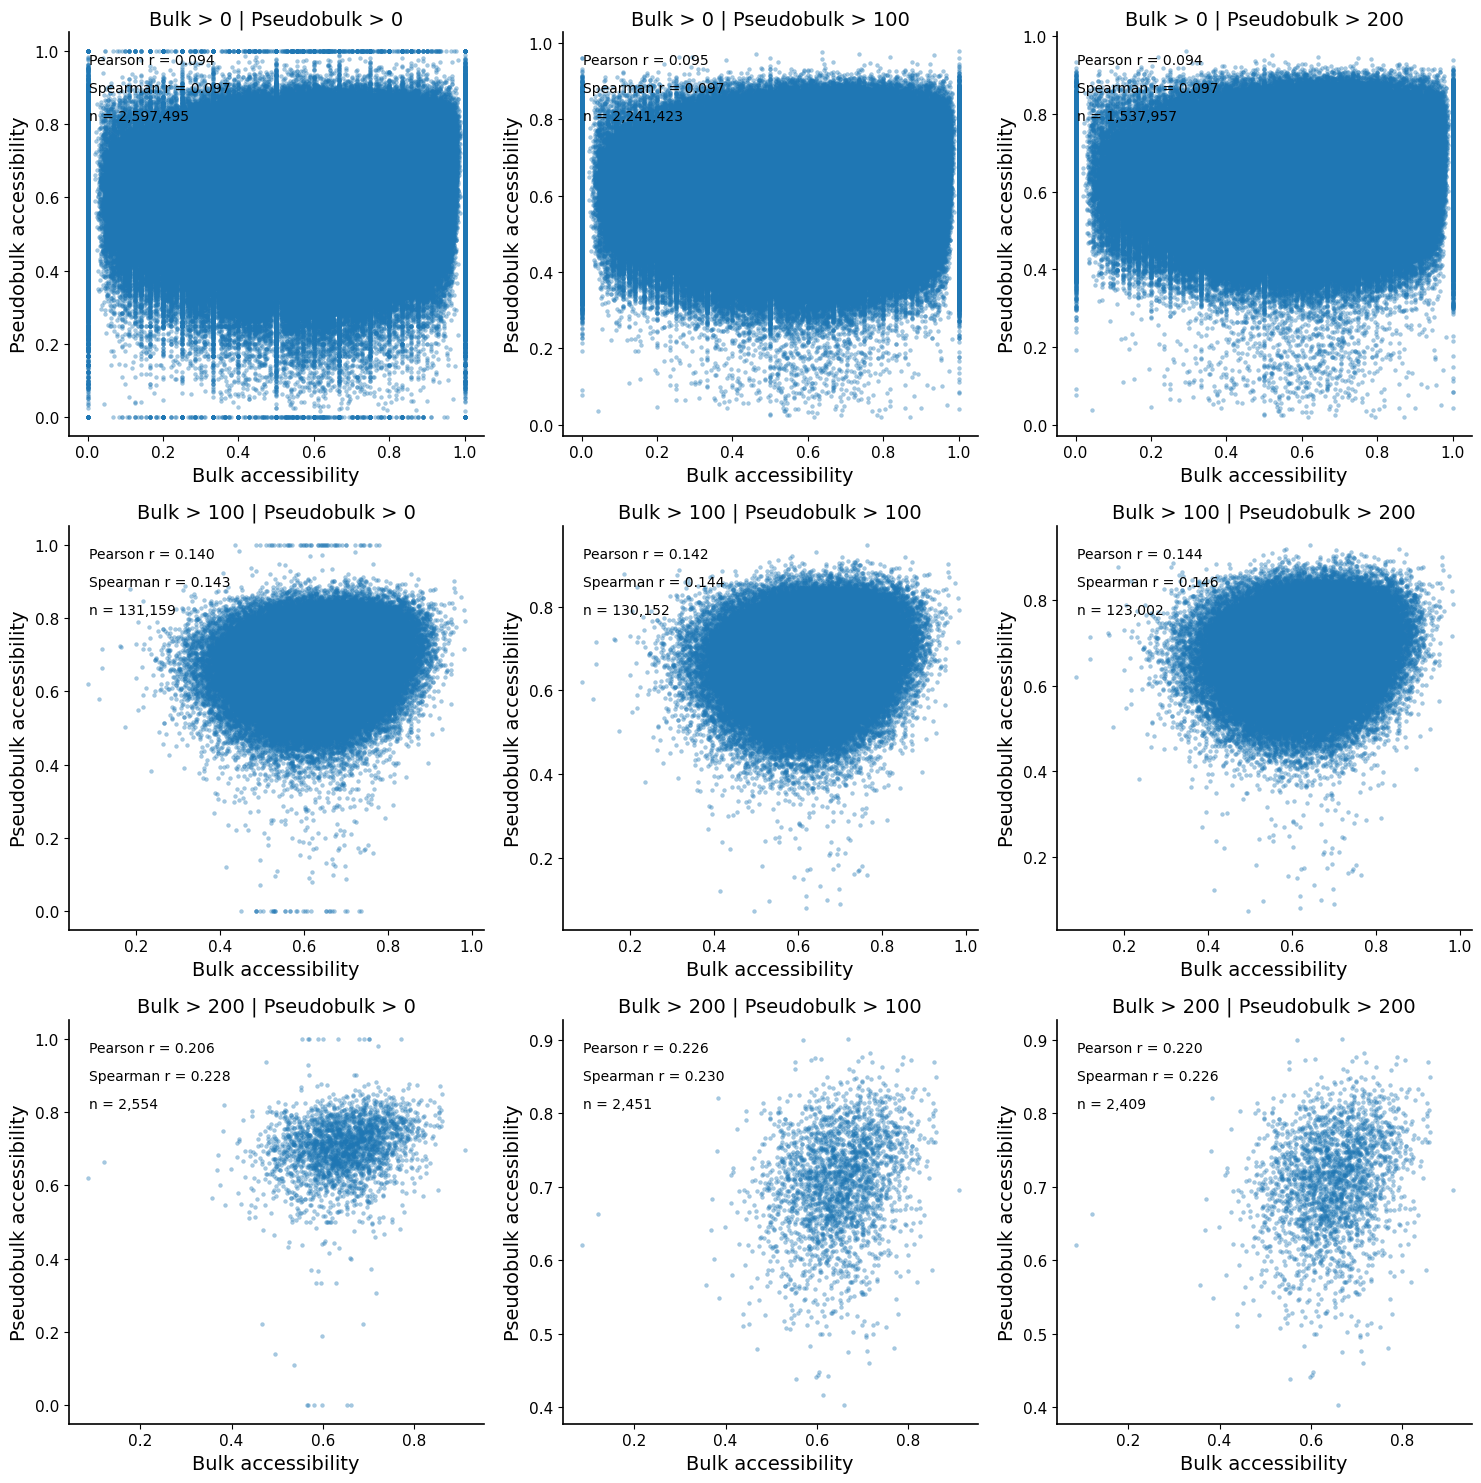

In [23]:
# Merge total_reads from BOTH sources into the merged dataframe
gm12878_acc = pd.merge(
    gm12878_acc_bulk[['chr', 'start', 'end', 'gm12878_acc_bulk', 'total_reads']],
    gm12878_acc_pseudobulk[['chr', 'start', 'end', 'gm12878_acc_pseudobulk', 'total_reads']],
    on=['chr', 'start', 'end'],
    suffixes=('_bulk', '_pseudobulk')
)

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
pseudo_thresholds = [0, 100, 200]
bulk_thresholds = [0, 100, 200]

for i, bulk_thresh in enumerate(bulk_thresholds):
    for j, pseudo_thresh in enumerate(pseudo_thresholds):
        ax = axes[i, j]
        filtered = gm12878_acc.copy()
        if bulk_thresh > 0:
            filtered = filtered[filtered['total_reads_bulk'] > bulk_thresh]
        if pseudo_thresh > 0:
            filtered = filtered[filtered['total_reads_pseudobulk'] > pseudo_thresh]

        x = filtered['gm12878_acc_bulk'].to_numpy(dtype=float)
        y = filtered['gm12878_acc_pseudobulk'].to_numpy(dtype=float)
        mask = np.isfinite(x) & np.isfinite(y)
        x, y = x[mask], y[mask]

        pear_r, _ = pearsonr(x, y)
        spear_r, _ = spearmanr(x, y)

        sns.scatterplot(x=x, y=y, s=8, alpha=0.4, edgecolor=None, ax=ax)
        ax.set_xlabel("Bulk accessibility")
        ax.set_ylabel("Pseudobulk accessibility")
        ax.set_title(f"Bulk > {bulk_thresh} | Pseudobulk > {pseudo_thresh}")

        ax.text(0.05, 0.95, f"Pearson r = {pear_r:.3f}",
                transform=ax.transAxes, va='top', fontsize=10)
        ax.text(0.05, 0.88, f"Spearman r = {spear_r:.3f}",
                transform=ax.transAxes, va='top', fontsize=10)
        ax.text(0.05, 0.81, f"n = {len(x):,}",
                transform=ax.transAxes, va='top', fontsize=10)

sns.despine()
plt.tight_layout()
plt.savefig("../figures/GM12878_accessibility_correlation_3x3_thresholds.pdf")
plt.show()

In [33]:
gm12878_acc

,chr,start,end,gm12878_acc_bulk,gm12878_acc_pseudobulk
0,chr1,2021000,2022000,0.703704,0.781129
1,chr1,2042000,2043000,0.576923,0.680000
2,chr1,2070000,2071000,0.774892,0.826772
3,chr1,2084000,2085000,0.644231,0.775981
4,chr1,2654000,2655000,0.703158,0.760349
...,...,...,...,...,...
2404,chr22,48720000,48721000,0.585903,0.727273
2405,chr22,49159000,49160000,0.741036,0.796899
2406,chr22,49704000,49705000,0.672932,0.754644
2407,chr22,49928000,49929000,0.599034,0.833466


In [9]:
import numpy as np

def quantile_normalize(target, reference):
    """
    Quantile normalize 'target' distribution to match 'reference'.
    
    target: array-like (e.g., pseudobulk)
    reference: array-like (e.g., bulk)
    """
    target = np.asarray(target, dtype=float)
    reference = np.asarray(reference, dtype=float)

    # sort both
    target_order = np.argsort(target)
    ref_sorted = np.sort(reference)

    # create output
    normalized = np.empty_like(target)

    # assign reference quantiles to target ranks
    normalized[target_order] = ref_sorted

    return normalized

In [89]:
gm_bulk_methy_points = pd.read_csv('../bulk_gm/GM12878_bulk_HCG.bed', sep='\t', header=None, names=['chr', 'start', 'end', 'methy','cov'])
gm_bulk_methy_points['methy_level_bulk'] = gm_bulk_methy_points['methy']/gm_bulk_methy_points['cov']

In [97]:
gm_pseudobulk_methy_points = pd.read_csv('HCG_merged.bed', sep='\t', header=None, names=['chr', 'start', 'end', 'methy','cov'], skiprows=1)
gm_pseudobulk_methy_points['methy_level_pseudobulk'] = gm_pseudobulk_methy_points['methy']/gm_pseudobulk_methy_points['cov']

In [113]:
gm_pseudobulk_methy_points = gm_pseudobulk_methy_points[gm_pseudobulk_methy_points['cov'] > 10]
gm_bulk_methy_points = gm_bulk_methy_points[gm_bulk_methy_points['cov'] > 10]

In [114]:
merged = pd.merge(gm_bulk_methy_points, gm_pseudobulk_methy_points, on=['chr', 'start', 'end'], how='inner')

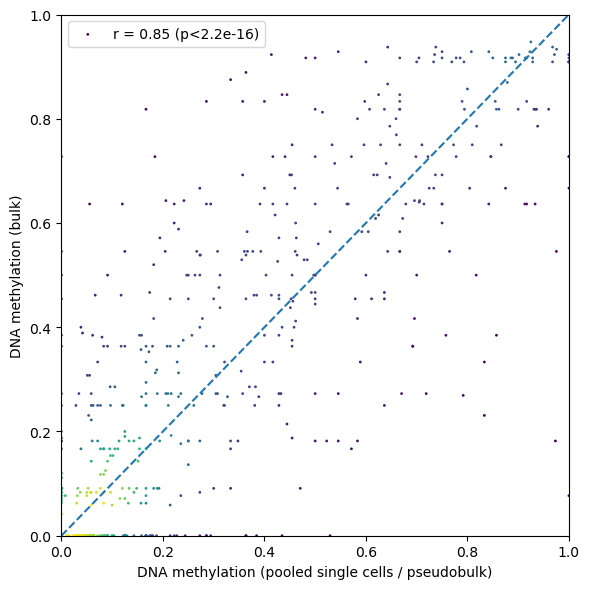

In [117]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, pearsonr

# --- sanity: avoid div-by-zero and non-numeric ---
for df, mcol, ccol, outcol in [
    (gm_bulk_methy_points, "methy", "cov", "methy_level_bulk"),
    (gm_pseudobulk_methy_points, "methy", "cov", "methy_level_pseudobulk"),
]:
    df[mcol] = pd.to_numeric(df[mcol], errors="coerce")
    df[ccol] = pd.to_numeric(df[ccol], errors="coerce")
    df[outcol] = df[mcol] / df[ccol]
    df.loc[(df[ccol] <= 0) | (~np.isfinite(df[outcol])), outcol] = np.nan

merged = pd.merge(
    gm_bulk_methy_points[["chr","start","end","methy_level_bulk"]],
    gm_pseudobulk_methy_points[["chr","start","end","methy_level_pseudobulk"]],
    on=["chr","start","end"],
    how="inner"
).dropna()

x = merged["methy_level_pseudobulk"].to_numpy(dtype=float)
y = merged["methy_level_bulk"].to_numpy(dtype=float)

# --- choose axis scaling: if looks like 0-1, keep; if looks like 0-100, keep ---
vals = np.concatenate([x, y]) if (len(x) and len(y)) else np.array([np.nan])
mx = np.nanmax(vals)
if np.isfinite(mx) and mx <= 1.2:
    xlim = ylim = (0.0, 1.0)
    xlabel = "DNA methylation (pooled single cells / pseudobulk)"
    ylabel = "DNA methylation (bulk)"
else:
    # treat as percent scale if values are ~0..100
    xlim = ylim = (0.0, 100.0)
    xlabel = "DNA methylation (pooled single cells / pseudobulk, %)"
    ylabel = "DNA methylation (bulk, %)"

# --- KDE density coloring (like smoothScatter) ---
# For very large N, KDE can be slow; subsample for coloring but compute r on full data.
N = len(x)
max_kde = 20000000
if N > max_kde:
    rng = np.random.default_rng(0)
    idx = rng.choice(N, size=max_kde, replace=False)
    x_k, y_k = x[idx], y[idx]
else:
    x_k, y_k = x, y

xy = np.vstack([x_k, y_k])
z = gaussian_kde(xy)(xy)

# plot low density first, high density last
order = np.argsort(z)
xk, yk, zk = x_k[order], y_k[order], z[order]

# --- correlation on full data ---
r, p = pearsonr(x, y)
p_text = "p<2.2e-16" if p < 2.2e-16 else f"p={p:.2e}"

plt.figure(figsize=(6, 6))
plt.scatter(xk, yk, c=zk, s=4, linewidths=0, cmap="viridis")
plt.plot([xlim[0], xlim[1]], [ylim[0], ylim[1]], linestyle="--")  # y=x
plt.xlim(*xlim)
plt.ylim(*ylim)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
plt.legend([f"r = {r:.2f} ({p_text})"], loc="upper left", frameon=True)
plt.tight_layout()
plt.show()